# QuickBasket — Task 1: Exploratory Data Analysis
This notebook performs EDA over the QuickBasket dataset: loads data, cleans/merges, and answers the 7 required sub-tasks with clear plots and tables.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Display settings
pd.set_option("display.max_rows", 50)
pd.set_option("display.max_columns", 50)


## 1. Load Data

In [2]:

order_metadata = pd.read_csv(  "order_metadata.csv")
order_items_prior = pd.read_csv(  "order_items__prior.csv")
order_items_train = pd.read_csv(  "order_items__train.csv")

product_catalog = pd.read_csv(  "product_catalog.csv")
aisle_info = pd.read_csv(  "aisle_info.csv")
department_info = pd.read_csv(  "department_info.csv")

print(order_metadata.shape, order_items_prior.shape, order_items_train.shape)


(3421083, 7) (32434489, 4) (1384617, 4)


## 2. Prepare Lookups & Combined Order Items

In [3]:
prod_lookup = (
    product_catalog
    .merge(aisle_info, on="aisle_id", how="left")
    .merge(department_info, on="department_id", how="left")
)

order_items_all = pd.concat([order_items_prior, order_items_train], ignore_index=True)
order_items_all.head()


,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0
3,2,45918,4,1
4,2,30035,5,0


## 3. Total Orders & Unique Customers

In [4]:
total_orders = order_metadata["order_id"].nunique()
unique_customers = order_metadata["user_id"].nunique()
print(f"Total Orders: {total_orders}")
print(f"Unique Customers: {unique_customers}")


Total Orders: 3421083
Unique Customers: 206209


## 4. Unique Products, Aisles, Departments

In [5]:
unique_products = product_catalog["product_id"].nunique()
unique_aisles = aisle_info["aisle_id"].nunique()
unique_departments = department_info["department_id"].nunique()

print(f"Unique Products: {unique_products}")
print(f"Unique Aisles: {unique_aisles}")
print(f"Unique Departments: {unique_departments}")


Unique Products: 49688
Unique Aisles: 134
Unique Departments: 21


## 5. Top 20 Most Frequently Ordered Products

In [6]:
top_products = (
    order_items_all.groupby("product_id", as_index=False).size().rename(columns={"size": "order_count"})
    .merge(prod_lookup[["product_id", "product_name"]], on="product_id", how="left")
    .sort_values("order_count", ascending=False).head(20)
)
top_products


,product_id,order_count,product_name
24849,24852,491291,Banana
13173,13176,394930,Bag of Organic Bananas
21134,21137,275577,Organic Strawberries
21900,21903,251705,Organic Baby Spinach
47205,47209,220877,Organic Hass Avocado
47762,47766,184224,Organic Avocado
47622,47626,160792,Large Lemon
16794,16797,149445,Strawberries
26206,26209,146660,Limes
27842,27845,142813,Organic Whole Milk


## 6. Top Departments & Aisles by Order Volume (with Plots)

In [7]:
dept_volume = (
    order_items_all.merge(prod_lookup[["product_id", "department", "aisle"]], on="product_id", how="left")
    .groupby("department", as_index=False).size().rename(columns={"size": "order_count"})
    .sort_values("order_count", ascending=False)
)

aisle_volume = (
    order_items_all.merge(prod_lookup[["product_id", "department", "aisle"]], on="product_id", how="left")
    .groupby("aisle", as_index=False).size().rename(columns={"size": "order_count"})
    .sort_values("order_count", ascending=False)
)

dept_volume.head(20)


,department,order_count
19,produce,9888378
7,dairy eggs,5631067
20,snacks,3006412
3,beverages,2804175
10,frozen,2336858
16,pantry,1956819
2,bakery,1225181
6,canned goods,1114857
8,deli,1095540
9,dry goods pasta,905340


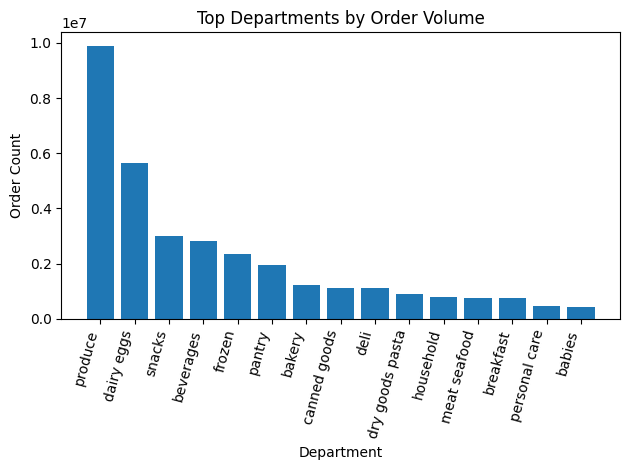

In [8]:
# Plot: Top Departments (Top 15)
plt.figure()
plot_dept = dept_volume.head(15)
plt.bar(plot_dept["department"].astype(str), plot_dept["order_count"])
plt.xticks(rotation=75, ha="right")
plt.title("Top Departments by Order Volume")
plt.xlabel("Department")
plt.ylabel("Order Count")
plt.tight_layout()


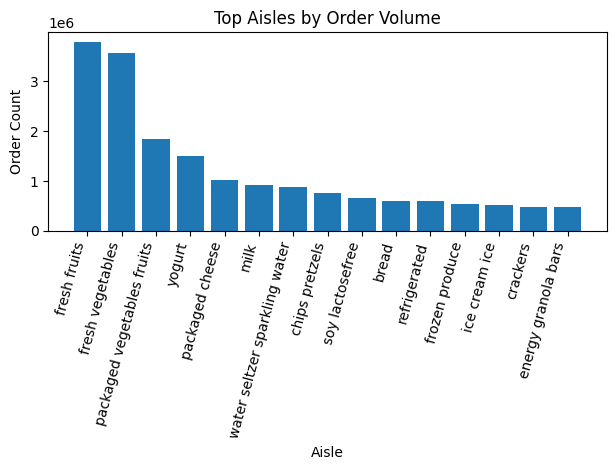

In [9]:
# Plot: Top Aisles (Top 15)
plt.figure()
plot_aisle = aisle_volume.head(15)
plt.bar(plot_aisle["aisle"].astype(str), plot_aisle["order_count"])
plt.xticks(rotation=75, ha="right")
plt.title("Top Aisles by Order Volume")
plt.xlabel("Aisle")
plt.ylabel("Order Count")
plt.tight_layout()


## 7. Most Reordered Products (Reorder Rate)

In [10]:
if "reordered" in order_items_all.columns:
    prod_reorders = (
        order_items_all.groupby("product_id", as_index=False)
        .agg(orders=("product_id", "size"), reorders=("reordered", "sum"))
    )
    prod_reorders["reorder_rate"] = prod_reorders["reorders"] / prod_reorders["orders"]
    prod_reorders = prod_reorders[prod_reorders["orders"] >= 50]  # filter low-support items
    top_reordered = (
        prod_reorders.merge(prod_lookup[["product_id", "product_name"]], on="product_id", how="left")
        .sort_values(["reorder_rate", "orders"], ascending=[False, False])
        .head(20)
    )
    top_reordered
else:
    print("Column 'reordered' not found in order items tables; cannot compute reorder rates.")


## 8. Average Basket Size

In [11]:
basket_sizes = order_items_all.groupby("order_id", as_index=False).size().rename(columns={"size": "basket_size"})
avg_basket_size = basket_sizes["basket_size"].mean()
avg_basket_size


np.float64(10.10707325550502)

## 9. Order Trends (Hour of Day, Day of Week, Days Since Prior Order)

,order_hour_of_day,size
0,0,22758
1,1,12398
2,2,7539
3,3,5474
4,4,5527


,order_dow,size
0,0,600905
1,1,587478
2,2,467260
3,3,436972
4,4,426339


,days_since_prior_order,size
0,0.0,67755
1,1.0,145247
2,2.0,193206
3,3.0,217005
4,4.0,221696


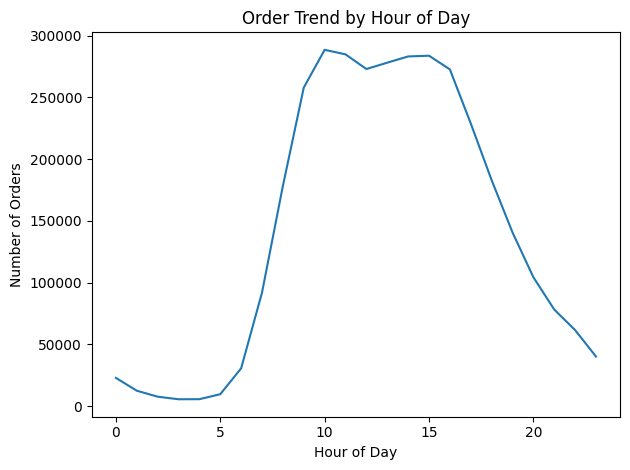

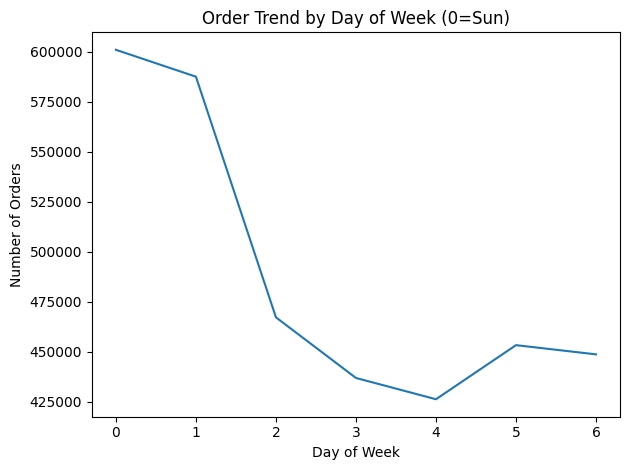

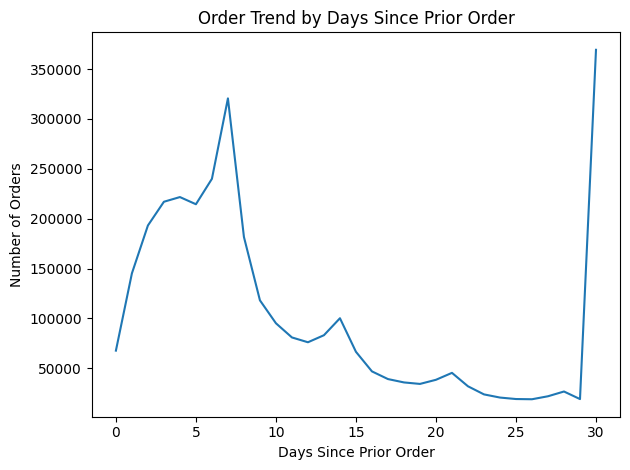

In [12]:
has_hour = "order_hour_of_day" in order_metadata.columns
has_dow = "order_dow" in order_metadata.columns
has_days_since = "days_since_prior_order" in order_metadata.columns

if has_hour:
    trend_hour = order_metadata.groupby("order_hour_of_day", as_index=False).size()
    display(trend_hour.head())
    plt.figure()
    plt.plot(trend_hour["order_hour_of_day"], trend_hour["size"])
    plt.title("Order Trend by Hour of Day")
    plt.xlabel("Hour of Day")
    plt.ylabel("Number of Orders")
    plt.tight_layout()

if has_dow:
    trend_dow = order_metadata.groupby("order_dow", as_index=False).size()
    display(trend_dow.head())
    plt.figure()
    plt.plot(trend_dow["order_dow"], trend_dow["size"])
    plt.title("Order Trend by Day of Week (0=Sun)")
    plt.xlabel("Day of Week")
    plt.ylabel("Number of Orders")
    plt.tight_layout()

if has_days_since:
    trend_days_since = order_metadata.groupby("days_since_prior_order", as_index=False).size()
    display(trend_days_since.head())
    plt.figure()
    plt.plot(trend_days_since["days_since_prior_order"], trend_days_since["size"])
    plt.title("Order Trend by Days Since Prior Order")
    plt.xlabel("Days Since Prior Order")
    plt.ylabel("Number of Orders")
    plt.tight_layout()
